In [1]:
# ============================================================
# IMPORTS AND CONFIGURATION
# ============================================================

import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists() and (PROJECT_DIR.parent / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "nox_residual_feature_shift"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# ============================================================
# LOAD AND PREPARE DATA
# ============================================================

files = sorted(DATA_DIR.glob("gt_*.csv"))
if not files:
    raise FileNotFoundError(f"No gt_*.csv files found in {DATA_DIR.resolve()}")

frames = []
for file in files:
    frame = pd.read_csv(file)
    frame["Year"] = int(file.stem.split("_")[-1])
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)

feature_cols = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]
required_cols = feature_cols + ["NOX", "Year"]

missing_cols = [col for col in required_cols if col not in data.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=required_cols).reset_index(drop=True)

print("Years found:", sorted(data["Year"].unique()))
print("Total observations:", len(data))
print(data.groupby("Year").size())

Years found: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]
Total observations: 36733
Year
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
dtype: int64


In [3]:
# ============================================================
# YEAR-WISE FEATURE AND NOX SUMMARY
# ============================================================

yearly_summary = data.groupby("Year")[feature_cols + ["NOX"]].agg(["mean", "std", "median"])
display(yearly_summary.round(3))
yearly_summary.to_csv(OUTPUT_DIR / "yearly_feature_nox_summary.csv")

AT                       AP                     AH                  \
        mean    std  median      mean    std  median    mean     std  median   
Year                                                                           
2011  17.112  7.428  16.366  1014.168  6.293  1013.6  79.175  13.466  82.129   
2012  18.398  7.661  19.120  1012.258  6.384  1012.0  79.075  14.105  82.412   
2013  17.603  6.863  17.204  1012.000  6.290  1011.8  80.462  14.125  84.002   
2014  18.217  6.995  18.284  1012.384  5.973  1012.0  82.144  13.000  84.656   
2015  17.225  8.096  17.456  1014.509  6.895  1014.0  68.647  13.541  70.952   

       AFDP  ...     TIT      TAT                    CDP                 \
       mean  ...  median     mean    std  median    mean    std  median   
Year         ...                                                          
2011  4.091  ...  1088.0  544.503  8.288  549.86  12.208  1.147  12.008   
2012  4.307  ...  1089.1  546.264  7.331  549.92  12.000  1.049  12.041   
2013  3.696  ...  1087.3  545.781  7.359  549.90  11.972  1.132  11.956   
2014  3.914  ...  1079.2  547.638  4.611  549.91  12.024  0.948  11.909   
2015  3.599  ...  1080.3  546.642  5.489  549.72  12.097  1.137  11.933   

         NOX                  
        mean     std  median  
Year                          
2011  67.575  10.683  65.542  
2012  68.789  10.225  67.246  
2013  70.008  12.048  68.651  
2014  60.067   9.972  59.278  
2015  59.891  11.132  56.838  

[5 rows x 27 columns]

In [4]:
# ============================================================
# FEATURE DISTRIBUTION SHIFT BETWEEN PERIODS
# ============================================================

early_period = data[data["Year"] <= 2013]
later_period = data[data["Year"] >= 2014]

shift_rows = []

for column in feature_cols + ["NOX"]:
    early_values = early_period[column].dropna()
    later_values = later_period[column].dropna()

    ks_statistic, ks_pvalue = ks_2samp(early_values, later_values)

    early_mean = early_values.mean()
    later_mean = later_values.mean()
    pooled_std = np.sqrt((early_values.var() + later_values.var()) / 2)

    standardized_mean_difference = (
        (later_mean - early_mean) / pooled_std
        if pooled_std > 0 else np.nan
    )

    shift_rows.append({
        "Variable": column,
        "Early_Mean_2011_2013": early_mean,
        "Later_Mean_2014_2015": later_mean,
        "Mean_Change": later_mean - early_mean,
        "Standardized_Mean_Difference": standardized_mean_difference,
        "KS_Statistic": ks_statistic,
        "KS_pvalue": ks_pvalue
    })

shift_results = pd.DataFrame(shift_rows).sort_values(
    "KS_Statistic", ascending=False
)
display(shift_results.round(4))
shift_results.to_csv(OUTPUT_DIR / "feature_distribution_shift.csv", index=False)

,Variable,Early_Mean_2011_2013,Later_Mean_2014_2015,Mean_Change,Standardized_Mean_Difference,KS_Statistic,KS_pvalue
8,NOX,68.7765,59.9773,-8.7992,-0.8141,0.3981,0.0000
5,TIT,1083.0803,1078.9068,-4.1734,-0.2376,0.3138,0.0000
3,AFDP,4.0378,3.7543,-0.2835,-0.3790,0.1867,0.0000
2,AH,79.5552,75.2908,-4.2644,-0.2959,0.1579,0.0000
6,TAT,545.5202,547.1326,1.6125,0.2467,0.1209,0.0000
4,GTEP,25.3179,25.9391,0.6212,0.1489,0.0967,0.0000
7,CDP,12.0602,12.0610,0.0008,0.0007,0.0805,0.0000
1,AP,1012.8126,1013.4632,0.6506,0.1005,0.0393,0.0000
0,AT,17.7122,17.7135,0.0012,0.0002,0.0211,0.0008


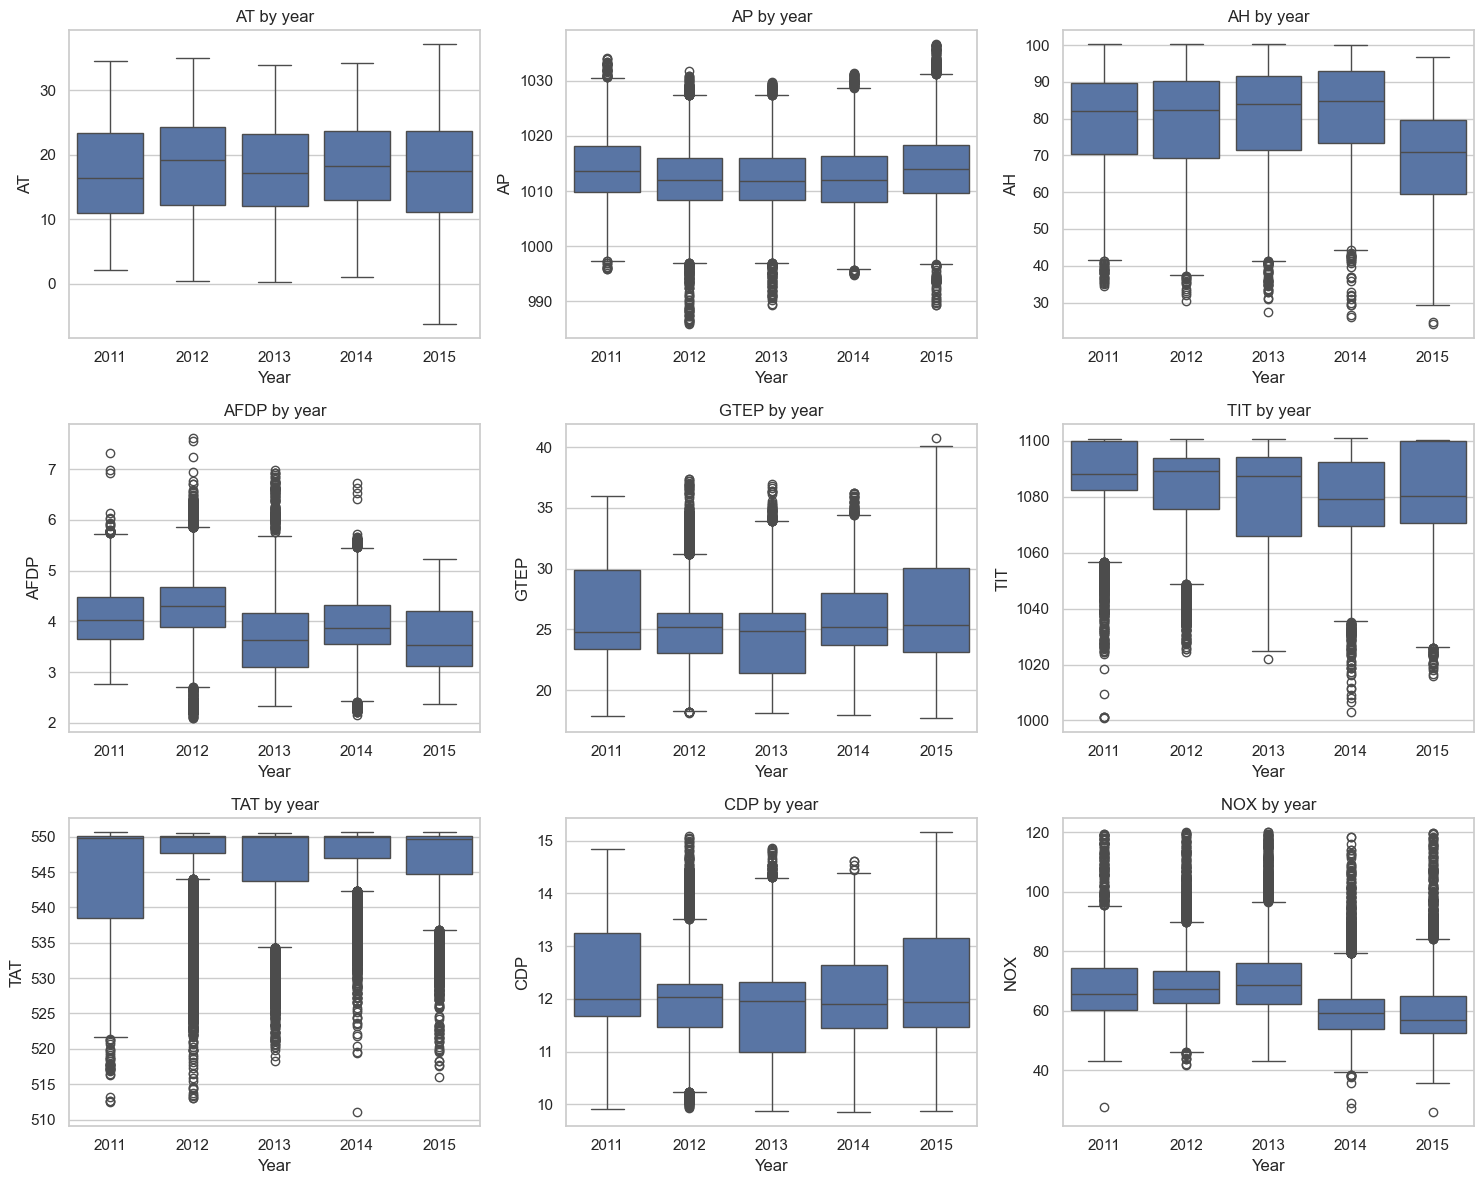

In [5]:
# ============================================================
# PLOT YEAR-WISE FEATURE DISTRIBUTIONS
# ============================================================

plot_columns = feature_cols + ["NOX"]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for ax, column in zip(axes, plot_columns):
    sns.boxplot(data=data, x="Year", y=column, ax=ax)
    ax.set_title(f"{column} by year")
    ax.set_xlabel("Year")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "yearly_feature_distributions.png", dpi=300)
plt.show()

Year,2011,2012,2013,2014,2015
Feature,,,,,
AFDP,-0.037,-0.054,-0.387,-0.385,-0.584
AH,0.209,0.081,0.183,0.071,0.065
AP,0.390,0.148,0.097,0.378,0.214
AT,-0.651,-0.567,-0.582,-0.657,-0.594
CDP,-0.200,-0.126,-0.005,-0.110,-0.443
GTEP,-0.250,-0.158,-0.024,-0.117,-0.367
TAT,0.088,-0.093,-0.179,-0.227,0.054
TIT,-0.232,-0.227,-0.123,-0.237,-0.520


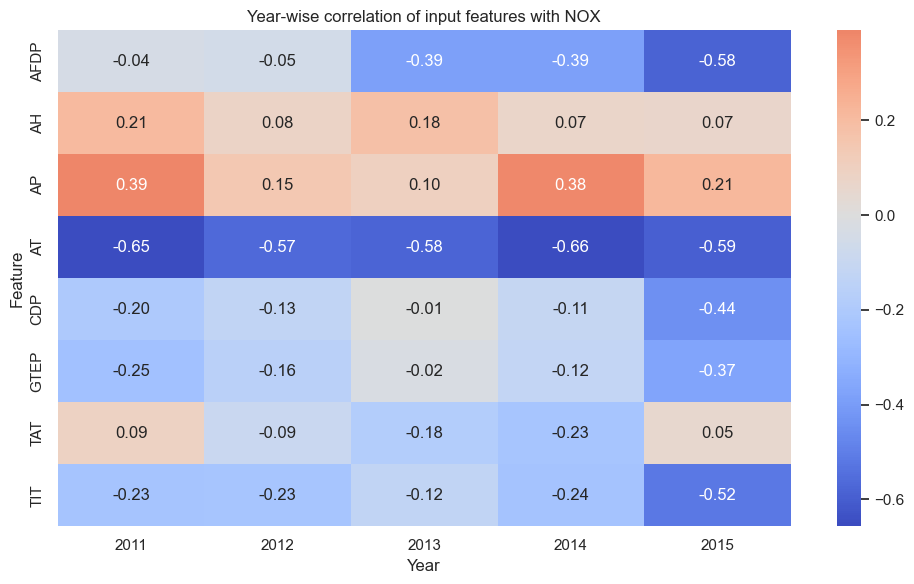

In [6]:
# ============================================================
# YEAR-WISE CORRELATION WITH NOX
# ============================================================

correlation_rows = []

for year, year_data in data.groupby("Year"):
    correlations = year_data[feature_cols + ["NOX"]].corr()["NOX"].drop("NOX")

    for feature, correlation in correlations.items():
        correlation_rows.append({
            "Year": year,
            "Feature": feature,
            "Correlation_with_NOX": correlation
        })

yearly_correlations = pd.DataFrame(correlation_rows)
correlation_pivot = yearly_correlations.pivot(
    index="Feature",
    columns="Year",
    values="Correlation_with_NOX"
)

display(correlation_pivot.round(3))
correlation_pivot.to_csv(OUTPUT_DIR / "yearly_feature_nox_correlations.csv")

plt.figure(figsize=(10, 6))
sns.heatmap(correlation_pivot, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Year-wise correlation of input features with NOX")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "yearly_feature_nox_correlation_heatmap.png", dpi=300)
plt.show()

In [7]:
# ============================================================
# FIT LINEAR REGRESSION AND GENERATE 2015 RESIDUALS
# ============================================================

development_data = data[data["Year"] <= 2014].copy()
comparison_data = data[data["Year"] == 2015].copy()

if development_data.empty or comparison_data.empty:
    raise ValueError("Required development years (2011–2014) or 2015 comparison data are missing.")

X_train = development_data[feature_cols]
y_train = development_data["NOX"]
X_test = comparison_data[feature_cols]
y_test = comparison_data["NOX"]

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_prediction = linear_model.predict(X_test)
residuals = y_test.to_numpy() - y_prediction

metrics = pd.DataFrame([{
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, y_prediction),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_prediction)),
    "R2": r2_score(y_test, y_prediction)
}])

display(metrics.round(4))
metrics.to_csv(OUTPUT_DIR / "linear_regression_2015_residual_metrics.csv", index=False)

residual_data = comparison_data[["Year"] + feature_cols + ["NOX"]].copy()
residual_data["Predicted_NOX"] = y_prediction
residual_data["Residual"] = residuals
residual_data["Absolute_Error"] = np.abs(residuals)
residual_data["Error_Direction"] = np.where(
    residual_data["Residual"] >= 0,
    "Underprediction",
    "Overprediction"
)

residual_data.to_csv(OUTPUT_DIR / "linear_regression_2015_residuals.csv", index=False)

,Model,MAE,RMSE,R2
0,Linear Regression,8.181,10.2146,0.158


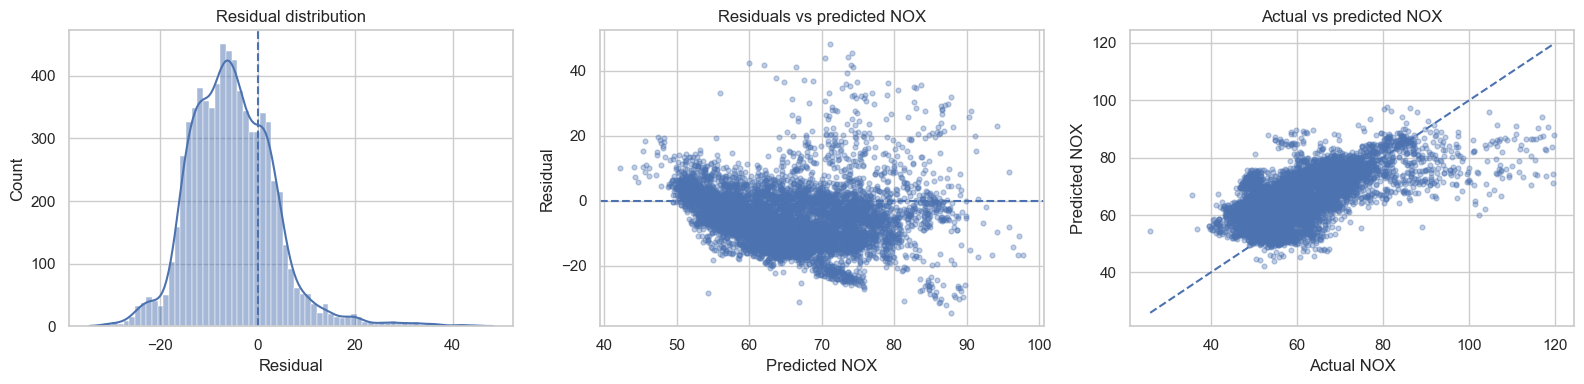

In [8]:
# ============================================================
# RESIDUAL DISTRIBUTION AND PREDICTED-VALUE DIAGNOSTICS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(residual_data["Residual"], kde=True, ax=axes[0])
axes[0].axvline(0, linestyle="--")
axes[0].set_title("Residual distribution")

axes[1].scatter(
    residual_data["Predicted_NOX"],
    residual_data["Residual"],
    alpha=0.35,
    s=12
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs predicted NOX")
axes[1].set_xlabel("Predicted NOX")
axes[1].set_ylabel("Residual")

axes[2].scatter(
    residual_data["NOX"],
    residual_data["Predicted_NOX"],
    alpha=0.35,
    s=12
)
lower = min(residual_data["NOX"].min(), residual_data["Predicted_NOX"].min())
upper = max(residual_data["NOX"].max(), residual_data["Predicted_NOX"].max())
axes[2].plot([lower, upper], [lower, upper], linestyle="--")
axes[2].set_title("Actual vs predicted NOX")
axes[2].set_xlabel("Actual NOX")
axes[2].set_ylabel("Predicted NOX")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "linear_regression_2015_residual_diagnostics.png", dpi=300)
plt.show()

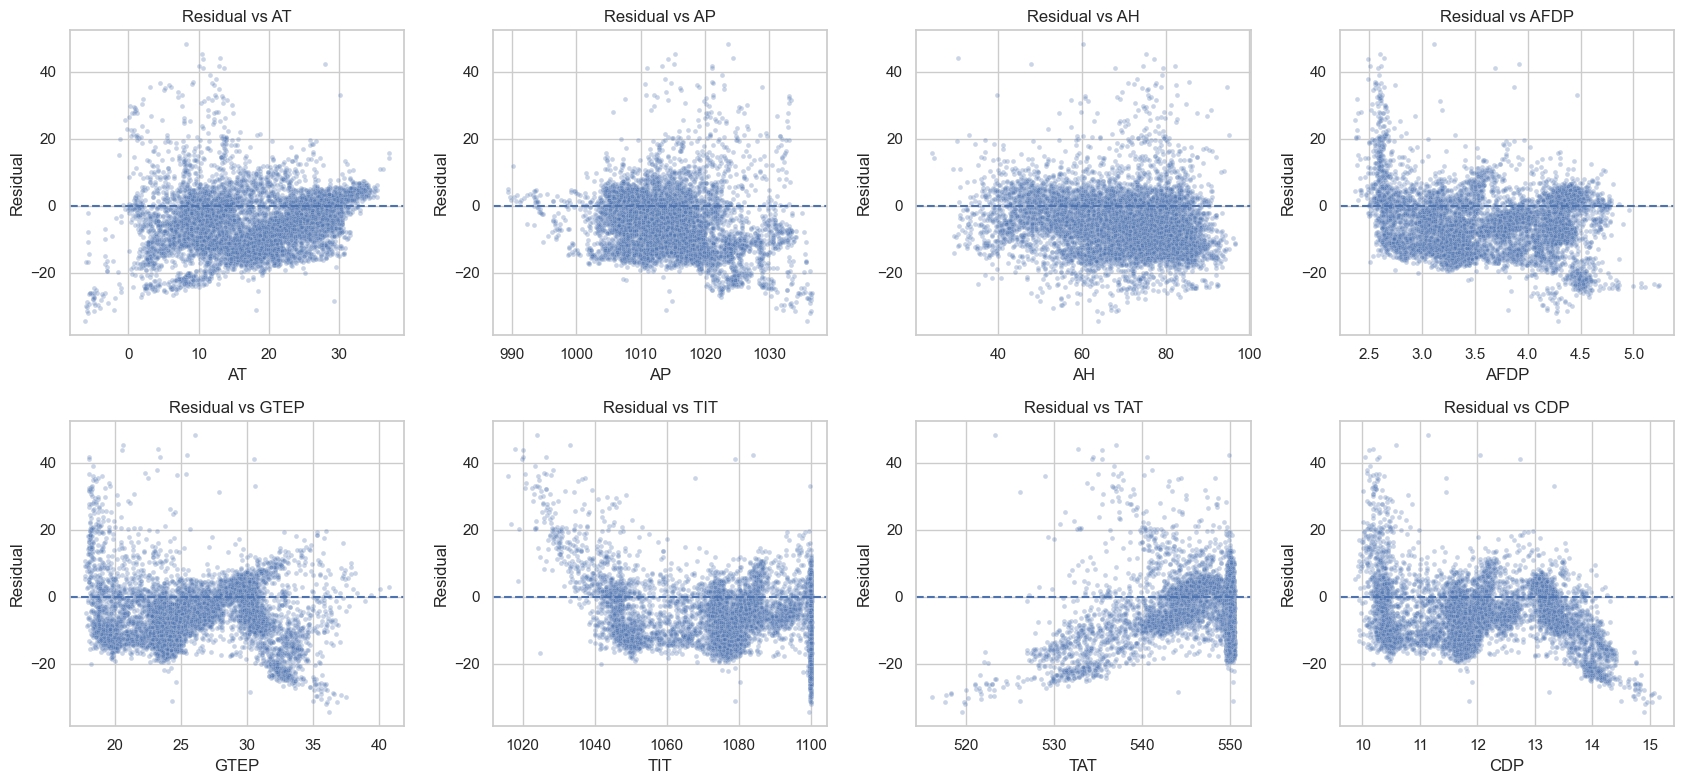

In [9]:
# ============================================================
# RESIDUALS AGAINST EACH OPERATING FEATURE
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.ravel()

for ax, feature in zip(axes, feature_cols):
    sns.scatterplot(
        data=residual_data,
        x=feature,
        y="Residual",
        alpha=0.3,
        s=12,
        ax=ax
    )
    ax.axhline(0, linestyle="--")
    ax.set_title(f"Residual vs {feature}")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "residuals_by_operating_feature.png", dpi=300)
plt.show()

In [10]:
# ============================================================
# ERROR BY OPERATING FEATURE BINS
# ============================================================

binned_error_rows = []

for feature in feature_cols:
    try:
        feature_bins = pd.qcut(
            residual_data[feature],
            q=5,
            duplicates="drop"
        )

        grouped = residual_data.groupby(feature_bins, observed=True).agg(
            Samples=("Residual", "size"),
            Mean_Feature=(feature, "mean"),
            Mean_Residual=("Residual", "mean"),
            MAE=("Absolute_Error", "mean"),
            RMSE=("Residual", lambda values: np.sqrt(np.mean(values ** 2)))
        ).reset_index(drop=True)

        grouped["Feature"] = feature
        binned_error_rows.append(grouped)

    except ValueError:
        print(f"Skipped binning for {feature}")

binned_errors = pd.concat(binned_error_rows, ignore_index=True)
display(binned_errors.round(4))
binned_errors.to_csv(OUTPUT_DIR / "residual_error_by_feature_bins.csv", index=False)

,Samples,Mean_Feature,Mean_Residual,MAE,RMSE,Feature
0,1477,5.7796,-5.7601,10.0606,12.7716,AT
1,1478,12.2929,-4.5026,8.5759,10.9850,AT
2,1475,17.3859,-8.0944,10.0055,11.1166,AT
3,1477,22.3435,-5.8515,7.4686,8.6590,AT
4,1477,28.3279,-1.8258,4.7968,6.2738,AT
5,1501,1005.7587,-3.3749,6.0188,7.5561,AP
6,1488,1010.7179,-4.1887,6.7183,8.4555,AP
7,1457,1014.0283,-4.2422,6.8217,8.5782,AP
8,1463,1017.4193,-6.0240,8.5460,9.9913,AP
9,1475,1024.8267,-8.2362,12.8378,14.8457,AP


In [11]:
# ============================================================
# OVERPREDICTION AND UNDERPREDICTION SUMMARY
# ============================================================

error_direction_summary = residual_data.groupby("Error_Direction").agg(
    Samples=("Residual", "size"),
    Mean_Absolute_Error=("Absolute_Error", "mean"),
    Mean_Residual=("Residual", "mean")
)

error_direction_summary["Percentage"] = (
    100 * error_direction_summary["Samples"] / len(residual_data)
)

display(error_direction_summary.round(3))
error_direction_summary.to_csv(
    OUTPUT_DIR / "over_under_prediction_summary.csv"
)

,Samples,Mean_Absolute_Error,Mean_Residual,Percentage
Error_Direction,,,,
Overprediction,5507,8.975,-8.975,74.58
Underprediction,1877,5.852,5.852,25.42


In [12]:
# ============================================================
# EXPORT FINAL ANALYSIS TABLES
# ============================================================

feature_shift_export = shift_results.copy()
feature_shift_export.to_csv(
    OUTPUT_DIR / "feature_shift_summary.csv",
    index=False
)

print("Analysis completed. Results saved to:", OUTPUT_DIR.resolve())

Analysis completed. Results saved to: C:\Users\devra\Music\gas-turbine-ml\outputs\nox_residual_feature_shift
